In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from solve_dae.integrate import solve_dae
import numpy as np
from rfbmodel1D.parameters.params import SimulationParams, Vars
from rfbmodel1D.cells.cell import Cell
import matplotlib.pyplot as plt
import rfbmodel1D
import time
import pandas as pd

In [ ]:
# ==============================================================================
# SIMULATION PARAMETERS 
# ==============================================================================
SOC          = 0.5                # [0-1] State of charge
V_tank       = 0.5 / 1000 *10000  # [m³] Tank volume
bc_mode      = "galvanostatic"    # Set BC mode to galvanostatic
j_appl       = -3500              # [A/m²] Applied current density (positive for discharge, negative for charge)
T            = 32+273.15          # [K] Temperature
t            = 200                # [s] Simulation time

In [34]:
# ---------------------------------------------------------------------
# Setup: Create cell and initialize parameters
# ---------------------------------------------------------------------
SimulationParams.CellParams.T = T
SimulationParams.CellParams.vanadium_uptake = False
sim_params = SimulationParams

cell = Cell(params=sim_params)
#cell.bc_mode = "potentiostatic"  # Set BC mode to potentiostatic
#cell.modify_BC(Vars.phi_el, "cathode", "left", "dirichlet", 1)
print("Cathode superficial velocity:", cell.cathode.u_ip, "m/s", "Channel velocity:", cell.cathode.u_ch)
print("Total flow rate:", cell.cathode.Q_total, " m3/s", "Cathode flow rate:", cell.cathode.Q_ca, " m3/s")

Cathode superficial velocity: 0.0027851635432568056 m/s Channel velocity: 0.1367654813136684
Total flow rate: 7.5e-07  m3/s Cathode flow rate: 6.405876149490653e-07  m3/s


In [35]:
# ==============================================================================
# Cell mode
# ==============================================================================
cell.bc_mode = bc_mode    # Set BC mode to galvanostatic
cell.modify_BC(Vars.phi_el, "cathode", "left", bc_mode, j_appl) # Set BC to galvanostatic with applied current density


In [36]:
# Derived tank concentrations from SOC
c_T_V4   = (1 - SOC) * 1000   # V(IV) concentration [mol/m³]
c_T_V5   = SOC * 1000         # V(V) concentration [mol/m³]
c_T_H    = 4963               # H+ concentration [mol/m³]
c_T_HSO4 = c_T_H * 3/5        # HSO4⁻ concentration [mol/m³]

# Tank state vector
c_0 = np.array([c_T_V4, c_T_V5, c_T_H, c_T_HSO4, V_tank])

# Initialize full DAE state from tank concentrations
# This will propagate the tank values through cathode, membrane, and anode

y0, yp0 = cell.initialize_dae_state(c_0, xtol=1e-6)

In [37]:
F        = 96485  # Faraday constant, C/mol
n        = 1      # electrons per reaction
C_active = 1000  # mol/m^3
Q_C      = n * F * V_tank * C_active * SOC  # Coulombs
Q_Ah_from_tank = Q_C / 3600            # Ampere-hours

In [38]:
Nc = cell.mesh.cathode_mesh.n_x
Nm = cell.mesh.membrane_mesh.n_x

# atol for variables
conc          = 1e-1
potential     = 1e-3
lambda_       = 1e-2
overpotential = 1e-4
saturation    = 1e-3
volume        = 1e-6
gas_conc      = 1e-3

# State-based absolute tolerances (not residual scales)
atol_tank = np.array([conc, conc, conc, conc, volume], dtype=float)
atol_cath_node = np.array([conc, conc, conc, conc, potential, potential], dtype=float)
atol_mem_node = np.array([lambda_, potential], dtype=float)   # lambda, phi_io
atol_anode = np.array([gas_conc, gas_conc, saturation, overpotential, gas_conc, gas_conc, saturation], dtype=float)
a_tol_coupling = np.array([conc], dtype=float)  # H+ concentration at cathode-membrane interface
   

atol = np.concatenate([
    atol_tank,
    np.tile(atol_cath_node, Nc),
    np.tile(atol_mem_node, Nm),
    atol_anode, a_tol_coupling
])

rtol = 1e-7

In [39]:
# ---------------------------
# Setup
# ---------------------------
t0 = 0.0
tf = t
# Solver settings
method = "BDF"
start_time = time.time()
sparsity_y, sparsity_yp = cell.compute_jac_sparsity(y0, yp0)
sol = solve_dae(
    cell.dae_residual_full_cell,
    (t0, tf),
    y0,
    yp0,
    method=method,
    atol=atol,
    rtol=rtol, jac_sparsity = (sparsity_y, sparsity_yp))
elapsed = time.time() - start_time
# Extract results
ysol = sol.y
tsol = sol.t
print(f"\n✓ Integration completed in {elapsed:.2f} s")
print(f"Success: {sol.success}")
print(f"Status: {sol.status}")
print(f"Reached time: {tsol[-1]:.6f} s")
print(f"Actual time points: {len(tsol)}")
print(f"Function evals: {sol.nfev}")
print(f"Jacobian evals: {sol.njev}")
print(f"LU decompositions: {sol.nlu}")
print(f"Message: {sol.message}")


✓ Integration completed in 13.67 s
Success: True
Status: 0
Reached time: 200.000000 s
Actual time points: 59
Function evals: 167
Jacobian evals: 10
LU decompositions: 32
Message: The solver successfully reached the end of the integration interval.


In [40]:
# Extract key variables at final time
y_final = ysol[:, -1]
Nc = cell.mesh.cathode_mesh.n_x
Nm = cell.mesh.membrane_mesh.n_x
n_tank = cell.layout.n_vars_tank
n_ca = cell.layout.n_vars_cathode
n_mem = cell.layout.n_vars_membrane
n_an = cell.layout.n_vars_anode
n_coupling = cell.layout.n_vars_coupling
off_tank = 0
off_ca = off_tank + n_tank
off_mem = off_ca + Nc * n_ca
off_an = off_mem + Nm * n_mem
off_coupling = off_an + n_an
# Extract final states
y_ca_final = y_final[off_ca:off_mem].reshape(Nc, n_ca)
y_mem_final = y_final[off_mem:off_an].reshape(Nm, n_mem)
y_an_final = y_final[off_an:off_an + n_an]
y_coupling_final = y_final[off_coupling:off_coupling + n_coupling]
# Anode variables
labels_an = ["c_vw_acl", "c_H2_acl", "s_acl", "eta_acl", "c_vw_agdl", "c_H2_agdl", "s_agdl"]


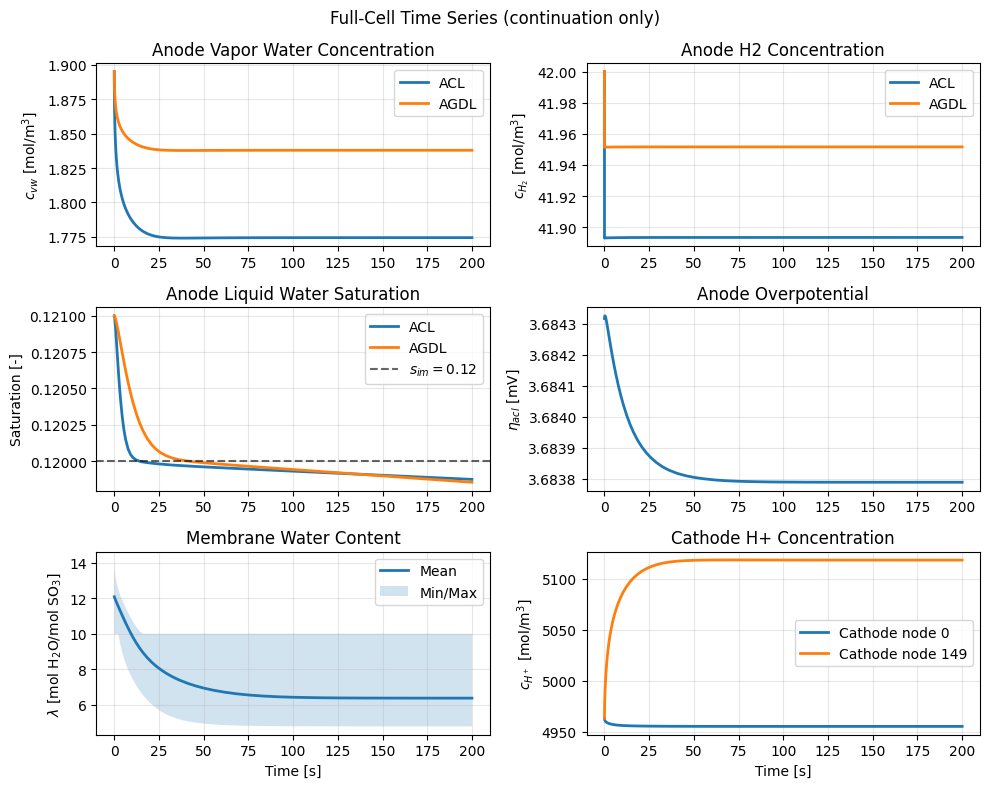

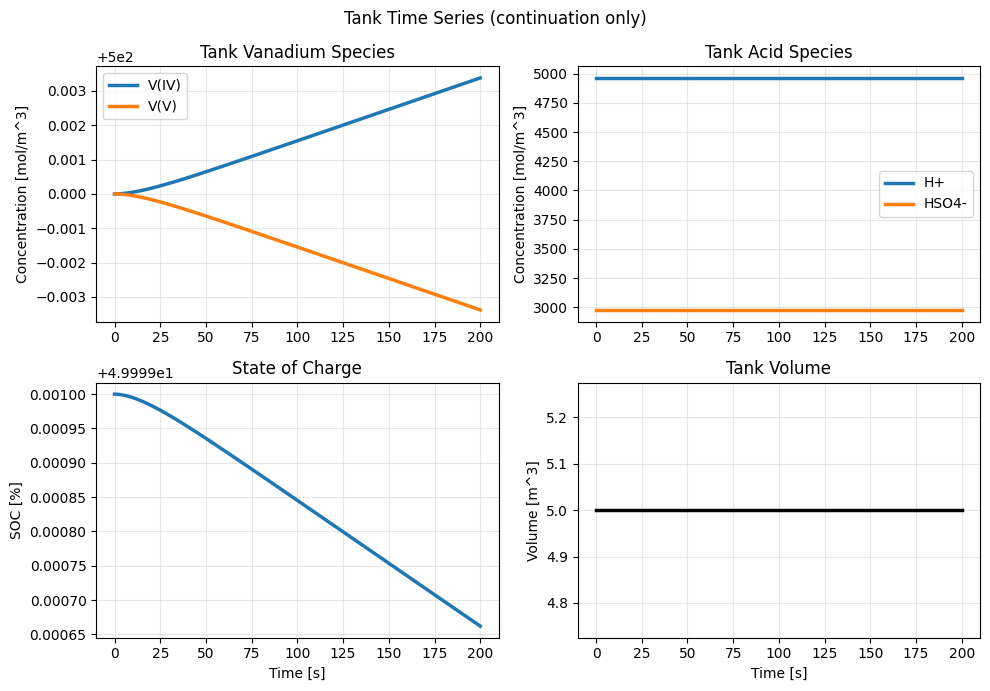

Time span plotted: 0.000000 -> 200.000000 s (59 points)


In [41]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Pick the best available solution data
# Priority: stitched history > continuation solution > base solution
# ------------------------------------------------------------
t_plot = tsol
y_plot = ysol
src_label = "continuation only"

# ------------------------------------------------------------
# Layout indices
# ------------------------------------------------------------
Nc = cell.mesh.cathode_mesh.n_x
Nm = cell.mesh.membrane_mesh.n_x

n_tank = cell.layout.n_vars_tank
n_ca = cell.layout.n_vars_cathode
n_mem = cell.layout.n_vars_membrane
n_an = cell.layout.n_vars_anode

off_tank = 0
off_ca = off_tank + n_tank
off_mem = off_ca + Nc * n_ca
off_an = off_mem + Nm * n_mem

# Domain reshapes over all times
y_ca_all = y_plot[off_ca:off_mem, :].reshape(Nc, n_ca, -1)     # (Nc, n_ca, Nt)
y_mem_all = y_plot[off_mem:off_an, :].reshape(Nm, n_mem, -1)   # (Nm, n_mem, Nt)
y_an_all = y_plot[off_an:off_an + n_an, :]                      # (n_an, Nt)

# ------------------------------------------------------------
# Extract full-cell variables
# ------------------------------------------------------------
c_vw_acl  = y_an_all[0, :]
c_H2_acl  = y_an_all[1, :]
s_acl     = y_an_all[2, :]
eta_acl   = y_an_all[3, :]
c_vw_agdl = y_an_all[4, :]
c_H2_agdl = y_an_all[5, :]
s_agdl    = y_an_all[6, :]

lambda_mem = y_mem_all[:, 0, :]
lambda_mem_mean = np.mean(lambda_mem, axis=0)
lambda_mem_min = np.min(lambda_mem, axis=0)
lambda_mem_max = np.max(lambda_mem, axis=0)

c_H_ca = y_ca_all[:, 2, :]
c_H_ca_first = c_H_ca[0, :]
c_H_ca_last  = c_H_ca[-1, :]

# ------------------------------------------------------------
# Extract tank variables
# ------------------------------------------------------------
tank_vars = y_plot[0:5, :]
c_V4   = tank_vars[0, :]
c_V5   = tank_vars[1, :]
c_H    = tank_vars[2, :]
c_HSO4 = tank_vars[3, :]
V_tank = tank_vars[4, :]

den = c_V4 + c_V5
SOC_time = np.divide(c_V5, den, out=np.zeros_like(c_V5), where=den > 0)

# ------------------------------------------------------------
# Figure 1: full-cell diagnostics
# ------------------------------------------------------------
fig1, axes = plt.subplots(3, 2, figsize=(10, 8))

axes[0, 0].plot(t_plot, c_vw_acl,  lw=2, label="ACL")
axes[0, 0].plot(t_plot, c_vw_agdl, lw=2, label="AGDL")
axes[0, 0].set_ylabel(r"$c_{vw}$ [mol/m$^3$]")
axes[0, 0].set_title("Anode Vapor Water Concentration")
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

axes[0, 1].plot(t_plot, c_H2_acl,  lw=2, label="ACL")
axes[0, 1].plot(t_plot, c_H2_agdl, lw=2, label="AGDL")
axes[0, 1].set_ylabel(r"$c_{H_2}$ [mol/m$^3$]")
axes[0, 1].set_title("Anode H2 Concentration")
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

axes[1, 0].plot(t_plot, s_acl,  lw=2, label="ACL")
axes[1, 0].plot(t_plot, s_agdl, lw=2, label="AGDL")
axes[1, 0].axhline(0.12, color="k", ls="--", alpha=0.6, label=r"$s_{im}=0.12$")
axes[1, 0].set_ylabel("Saturation [-]")
axes[1, 0].set_title("Anode Liquid Water Saturation")
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(t_plot, eta_acl * 1e3, lw=2)
axes[1, 1].set_ylabel(r"$\eta_{acl}$ [mV]")
axes[1, 1].set_title("Anode Overpotential")
axes[1, 1].grid(True, alpha=0.3)

axes[2, 0].plot(t_plot, lambda_mem_mean, lw=2, label="Mean")
axes[2, 0].fill_between(t_plot, lambda_mem_min, lambda_mem_max, alpha=0.2, label="Min/Max")
axes[2, 0].set_xlabel("Time [s]")
axes[2, 0].set_ylabel(r"$\lambda$ [mol H$_2$O/mol SO$_3$]")
axes[2, 0].set_title("Membrane Water Content")
axes[2, 0].grid(True, alpha=0.3)
axes[2, 0].legend()

axes[2, 1].plot(t_plot, c_H_ca_first, lw=2, label="Cathode node 0")
axes[2, 1].plot(t_plot, c_H_ca_last,  lw=2, label=f"Cathode node {Nc-1}")
axes[2, 1].set_xlabel("Time [s]")
axes[2, 1].set_ylabel(r"$c_{H^+}$ [mol/m$^3$]")
axes[2, 1].set_title("Cathode H+ Concentration")
axes[2, 1].grid(True, alpha=0.3)
axes[2, 1].legend()

fig1.suptitle(f"Full-Cell Time Series ({src_label})")
fig1.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figure 2: tank diagnostics
# ------------------------------------------------------------
fig2, ax2 = plt.subplots(2, 2, figsize=(10, 7))

ax2[0, 0].plot(t_plot, c_V4, lw=2.5, label="V(IV)")
ax2[0, 0].plot(t_plot, c_V5, lw=2.5, label="V(V)")
ax2[0, 0].set_ylabel("Concentration [mol/m^3]")
ax2[0, 0].set_title("Tank Vanadium Species")
ax2[0, 0].grid(True, alpha=0.3)
ax2[0, 0].legend()

ax2[0, 1].plot(t_plot, c_H, lw=2.5, label="H+")
ax2[0, 1].plot(t_plot, c_HSO4, lw=2.5, label="HSO4-")
ax2[0, 1].set_ylabel("Concentration [mol/m^3]")
ax2[0, 1].set_title("Tank Acid Species")
ax2[0, 1].grid(True, alpha=0.3)
ax2[0, 1].legend()

ax2[1, 0].plot(t_plot, SOC_time * 100, lw=2.5)
ax2[1, 0].set_xlabel("Time [s]")
ax2[1, 0].set_ylabel("SOC [%]")
ax2[1, 0].set_title("State of Charge")
ax2[1, 0].grid(True, alpha=0.3)

ax2[1, 1].plot(t_plot, V_tank, lw=2.5, color="k")
ax2[1, 1].set_xlabel("Time [s]")
ax2[1, 1].set_ylabel("Volume [m^3]")
ax2[1, 1].set_title("Tank Volume")
ax2[1, 1].grid(True, alpha=0.3)

fig2.suptitle(f"Tank Time Series ({src_label})")
fig2.tight_layout()
plt.show()

print(f"Time span plotted: {t_plot[0]:.6f} -> {t_plot[-1]:.6f} s ({t_plot.size} points)")

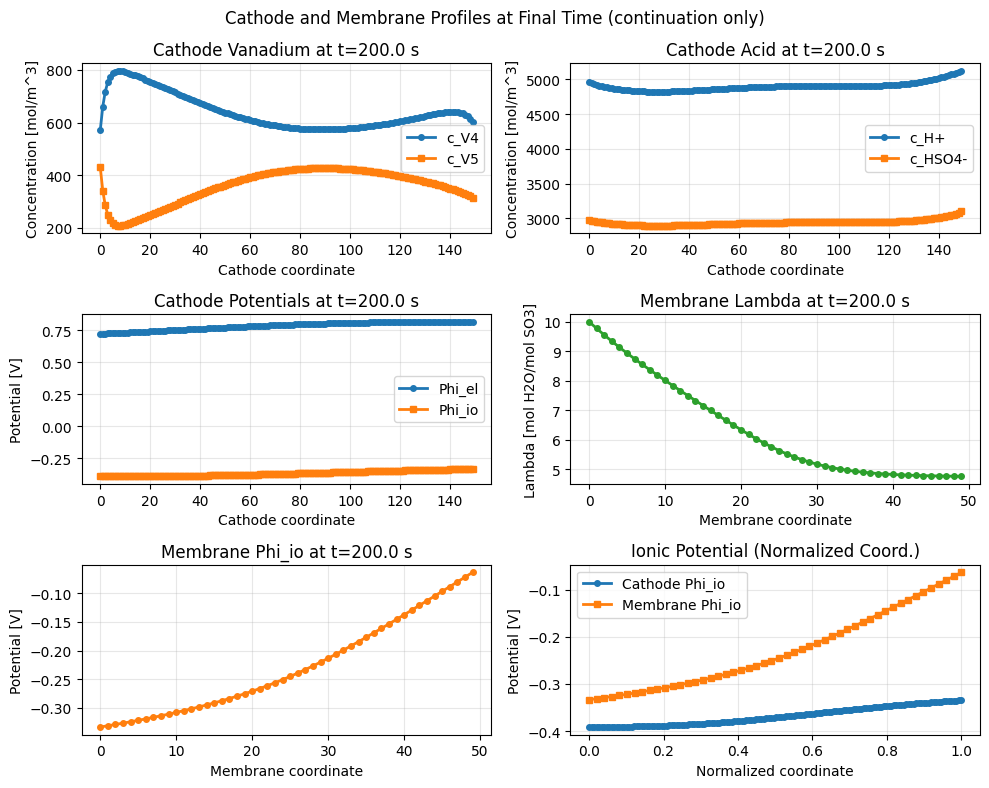

Last time used: 200.000000 s
Cathode c_H min/max: 4.822134e+03, 5.118514e+03
Membrane lambda min/max: 4.765251e+00, 9.995693e+00


In [42]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Use the most complete available solution
# ------------------------------------------------------------
t_plot = tsol
y_plot = ysol
src_label = "continuation only"

# Last-time state
y_last = y_plot[:, -1]
t_last = float(t_plot[-1])

# Layout
Nc = cell.mesh.cathode_mesh.n_x
Nm = cell.mesh.membrane_mesh.n_x

n_tank = cell.layout.n_vars_tank
n_ca = cell.layout.n_vars_cathode
n_mem = cell.layout.n_vars_membrane
n_an = cell.layout.n_vars_anode

off_tank = 0
off_ca = off_tank + n_tank
off_mem = off_ca + Nc * n_ca
off_an = off_mem + Nm * n_mem

# ------------------------------------------------------------
# Extract last-time cathode and membrane fields
# Cathode order: [c_V4, c_V5, c_H, c_HSO4, Phi_el, Phi_io]
# Membrane order: [lambda, Phi_io]
# ------------------------------------------------------------
y_ca_last = y_last[off_ca:off_mem].reshape(Nc, n_ca)
y_mem_last = y_last[off_mem:off_an].reshape(Nm, n_mem)

c_V4_ca = y_ca_last[:, 0]
c_V5_ca = y_ca_last[:, 1]
c_H_ca = y_ca_last[:, 2]
c_HSO4_ca = y_ca_last[:, 3]
phi_el_ca = y_ca_last[:, 4]
phi_io_ca = y_ca_last[:, 5]

lam_mem = y_mem_last[:, 0]
phi_io_mem = y_mem_last[:, 1]

# Prefer physical coordinates if available
if hasattr(cell.mesh.cathode_mesh, "x"):
    x_ca = np.asarray(cell.mesh.cathode_mesh.x)
elif hasattr(cell.mesh.cathode_mesh, "x_c"):
    x_ca = np.asarray(cell.mesh.cathode_mesh.x_c)
else:
    x_ca = np.arange(Nc)

if hasattr(cell.mesh.membrane_mesh, "x"):
    x_mem = np.asarray(cell.mesh.membrane_mesh.x)
elif hasattr(cell.mesh.membrane_mesh, "x_c"):
    x_mem = np.asarray(cell.mesh.membrane_mesh.x_c)
else:
    x_mem = np.arange(Nm)

# ------------------------------------------------------------
# Plot cathode + membrane profiles at final time
# ------------------------------------------------------------
fig, ax = plt.subplots(3, 2, figsize=(10, 8))

# Cathode species
ax[0, 0].plot(x_ca, c_V4_ca, "o-", lw=2, ms=4, label="c_V4")
ax[0, 0].plot(x_ca, c_V5_ca, "s-", lw=2, ms=4, label="c_V5")
ax[0, 0].set_title(f"Cathode Vanadium at t={t_last:.1f} s")
ax[0, 0].set_xlabel("Cathode coordinate")
ax[0, 0].set_ylabel("Concentration [mol/m^3]")
ax[0, 0].grid(True, alpha=0.3)
ax[0, 0].legend()

ax[0, 1].plot(x_ca, c_H_ca, "o-", lw=2, ms=4, label="c_H+")
ax[0, 1].plot(x_ca, c_HSO4_ca, "s-", lw=2, ms=4, label="c_HSO4-")
ax[0, 1].set_title(f"Cathode Acid at t={t_last:.1f} s")
ax[0, 1].set_xlabel("Cathode coordinate")
ax[0, 1].set_ylabel("Concentration [mol/m^3]")
ax[0, 1].grid(True, alpha=0.3)
ax[0, 1].legend()

# Cathode potentials
ax[1, 0].plot(x_ca, phi_el_ca, "o-", lw=2, ms=4, label="Phi_el")
ax[1, 0].plot(x_ca, phi_io_ca, "s-", lw=2, ms=4, label="Phi_io")
ax[1, 0].set_title(f"Cathode Potentials at t={t_last:.1f} s")
ax[1, 0].set_xlabel("Cathode coordinate")
ax[1, 0].set_ylabel("Potential [V]")
ax[1, 0].grid(True, alpha=0.3)
ax[1, 0].legend()

# Membrane profiles
ax[1, 1].plot(x_mem, lam_mem, "o-", lw=2, ms=4, color="tab:green")
ax[1, 1].set_title(f"Membrane Lambda at t={t_last:.1f} s")
ax[1, 1].set_xlabel("Membrane coordinate")
ax[1, 1].set_ylabel("Lambda [mol H2O/mol SO3]")
ax[1, 1].grid(True, alpha=0.3)

ax[2, 0].plot(x_mem, phi_io_mem, "o-", lw=2, ms=4, color="tab:orange")
ax[2, 0].set_title(f"Membrane Phi_io at t={t_last:.1f} s")
ax[2, 0].set_xlabel("Membrane coordinate")
ax[2, 0].set_ylabel("Potential [V]")
ax[2, 0].grid(True, alpha=0.3)

# Combined ionic potential comparison
x_ca_n = (x_ca - x_ca.min()) / (x_ca.max() - x_ca.min() + 1e-30)
x_mem_n = (x_mem - x_mem.min()) / (x_mem.max() - x_mem.min() + 1e-30)
ax[2, 1].plot(x_ca_n, phi_io_ca, "o-", lw=2, ms=4, label="Cathode Phi_io")
ax[2, 1].plot(x_mem_n, phi_io_mem, "s-", lw=2, ms=4, label="Membrane Phi_io")
ax[2, 1].set_title("Ionic Potential (Normalized Coord.)")
ax[2, 1].set_xlabel("Normalized coordinate")
ax[2, 1].set_ylabel("Potential [V]")
ax[2, 1].grid(True, alpha=0.3)
ax[2, 1].legend()

fig.suptitle(f"Cathode and Membrane Profiles at Final Time ({src_label})")
fig.tight_layout()
plt.show()

print(f"Last time used: {t_last:.6f} s")
print(f"Cathode c_H min/max: {c_H_ca.min():.6e}, {c_H_ca.max():.6e}")
print(f"Membrane lambda min/max: {lam_mem.min():.6e}, {lam_mem.max():.6e}")

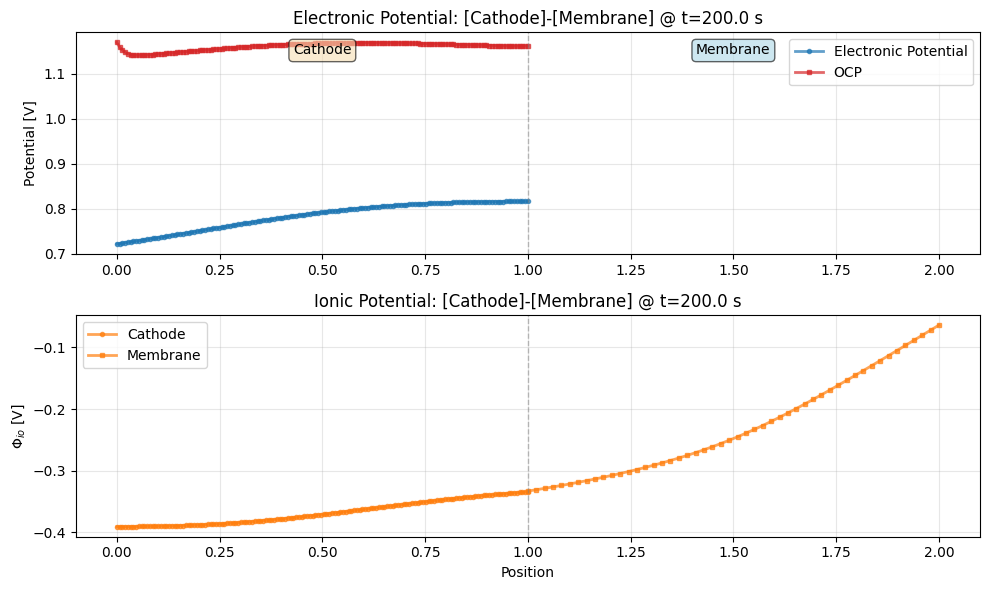

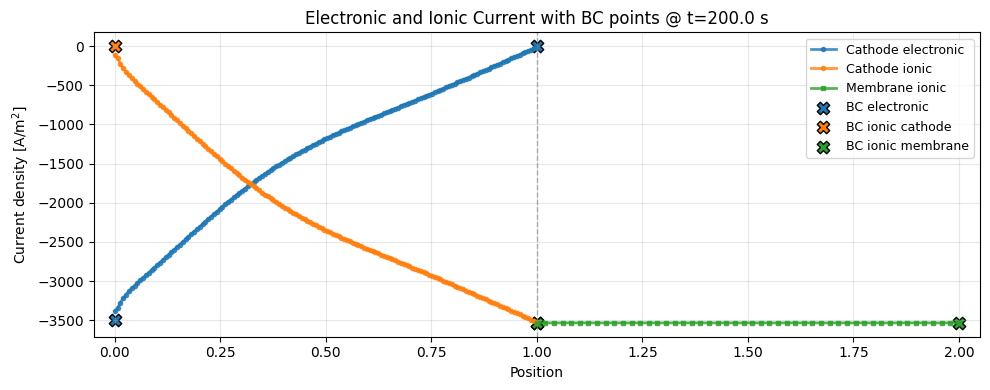

Electronic BC (left,right): galvanostatic neumann -> -3500.0 -0.0
Ionic cathode BC: neumann neumann -> -0.0 -3534.678215040504
Ionic membrane BC: neumann dirichlet -> -3534.678215040835 -3534.677025081898
Source used: continuation only


In [43]:
import numpy as np
import matplotlib.pyplot as plt

# ============= Use latest available solution (last time) =============
t_plot = tsol
y_plot = ysol
src_label = "continuation only"

y_last = y_plot[:, -1]
t_last = float(t_plot[-1])

# Layout
Nc = cell.mesh.cathode_mesh.n_x
Nm = cell.mesh.membrane_mesh.n_x
n_tank = cell.layout.n_vars_tank
n_ca = cell.layout.n_vars_cathode
n_mem = cell.layout.n_vars_membrane
off_tank = 0
off_ca = off_tank + n_tank
off_mem = off_ca + Nc * n_ca

# Last-time cathode/membrane states
y_ca_last = y_last[off_ca:off_mem].reshape(Nc, n_ca)
y_mem_last = y_last[off_mem:off_mem + Nm * n_mem].reshape(Nm, n_mem)

# Cathode order: [c_V4, c_V5, c_H, c_HSO4, Phi_el, Phi_io]
# Membrane order: [lambda, Phi_io]
c_ca = y_ca_last[:, :4]
phi_el_ca = y_ca_last[:, 4]
phi_io_ca = y_ca_last[:, 5]
phi_io_mem = y_mem_last[:, 1]

# Combined 1D plotting coordinates (dimensionless domains)
L_ca           = 1.0
L_mem          = 1.0
x_combined_ca  = np.linspace(0.0, L_ca, Nc)
x_combined_mem = np.linspace(L_ca, L_ca + L_mem, Nm)

# OCP in cathode at last time
V_OCP_ca = np.array([cell.compute_OCP(c_ca[i, :], "cathode") for i in range(Nc)])

# ============= PLOT 1: POTENTIALS (phi_el, phi_io) - Cathode & Membrane =============
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))

ax1.plot(x_combined_ca, phi_el_ca, "o-", lw=2, ms=3, label="Electronic Potential", color="tab:blue", alpha=0.7)
ax1.plot(x_combined_ca, V_OCP_ca, "s-", lw=2, ms=3, label="OCP", color="tab:red", alpha=0.7)
ax1.axvline(x=L_ca, color="gray", ls="--", alpha=0.5, lw=1)
ax1.set_ylabel("Potential [V]")
ax1.set_title(f"Electronic Potential: [Cathode]-[Membrane] @ t={t_last:.1f} s")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="best")
ax1.set_xlim(-0.1, L_ca + L_mem + 0.1)

y_range = ax1.get_ylim()
y_pos = y_range[0] + (y_range[1] - y_range[0]) * 0.90
ax1.text(L_ca / 2, y_pos, "Cathode", ha="center",
         bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.6))
ax1.text(L_ca + L_mem / 2, y_pos, "Membrane", ha="center",
         bbox=dict(boxstyle="round", facecolor="lightblue", alpha=0.6))

ax2.plot(x_combined_ca, phi_io_ca, "o-", lw=2, ms=3, label="Cathode", color="tab:orange", alpha=0.7)
ax2.plot(x_combined_mem, phi_io_mem, "s-", lw=2, ms=3, label="Membrane", color="tab:orange", alpha=0.7)
ax2.axvline(x=L_ca, color="gray", ls="--", alpha=0.5, lw=1)
ax2.set_xlabel("Position")
ax2.set_ylabel(r"$\Phi_{io}$ [V]")
ax2.set_title(f"Ionic Potential: [Cathode]-[Membrane] @ t={t_last:.1f} s")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="best")
ax2.set_xlim(-0.1, L_ca + L_mem + 0.1)

plt.tight_layout()
plt.show()

# ============= PLOT 2: Ionic + Electronic Current + BC points =============
def bc_to_current(phi, bc, coeff, dx, side):
    if bc.type == "neumann":
        dphi_dx = bc.value
    elif bc.type == "galvanostatic":
        dphi_dx = -bc.value / coeff
    elif bc.type == "dirichlet":
        if side == "left":
            dphi_dx = (phi[0] - bc.value) / (dx[0] / 2)
        elif side == "right":
            dphi_dx = (bc.value - phi[-1]) / (dx[-1] / 2)
        else:
            raise ValueError("side must be 'left' or 'right'")
    else:
        return np.nan
    return -coeff * dphi_dx

# Geometry and transport coefficients
dx_ca = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
dx_m = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
edges_m = np.concatenate([[0.0], np.cumsum(dx_m)])
edges_ca = np.concatenate([[0.0], np.cumsum(dx_ca)])
x_center_m = 0.5 * (edges_m[:-1] + edges_m[1:])
dx_face_m = x_center_m[1:] - x_center_m[:-1]
x_center_ca = 0.5 * (edges_ca[:-1] + edges_ca[1:])
dx_face_ca = x_center_ca[1:] - x_center_ca[:-1]

sigma_ca = float(cell.cathode.eff_conductivity)
kappa_ca = cell.cathode.kappa_io

kappa_m_arr = np.asarray(cell.membrane.kappa_io)
if kappa_m_arr.ndim == 0:
    kappa_m_arr = np.full(Nm, float(kappa_m_arr))

# Node-wise currents
grad_faces_ca = (phi_el_ca[1:] - phi_el_ca[:-1]) / dx_face_ca
grad_nodes_phi_el = np.empty_like(phi_el_ca)
grad_nodes_phi_el[0] = grad_faces_ca[0]
grad_nodes_phi_el[1:-1] = 0.5 * (grad_faces_ca[:-1] + grad_faces_ca[1:])
grad_nodes_phi_el[-1] = grad_faces_ca[-1]
grad_faces_io_ca = (phi_io_ca[1:] - phi_io_ca[:-1]) / dx_face_ca
grad_nodes_phi_io_ca = np.empty_like(phi_io_ca)
grad_nodes_phi_io_ca[0] = grad_faces_io_ca[0]
grad_nodes_phi_io_ca[1:-1] = 0.5 * (grad_faces_io_ca[:-1] + grad_faces_io_ca[1:])
grad_nodes_phi_io_ca[-1] = grad_faces_io_ca[-1]
i_el_ca = -sigma_ca * grad_nodes_phi_el
i_io_ca = -kappa_ca * grad_nodes_phi_io_ca

bc_phi_el_ca_L = cell.bc[Vars.phi_el]["cathode"]["left"]
bc_phi_el_ca_R = cell.bc[Vars.phi_el]["cathode"]["right"]
bc_phi_io_ca_L = cell.bc[Vars.phi_io]["cathode"]["left"]
bc_phi_io_ca_R = cell.bc[Vars.phi_io]["cathode"]["right"]
bc_phi_io_m_L = cell.bc[Vars.phi_io]["membrane"]["left"]
bc_phi_io_m_R = cell.bc[Vars.phi_io]["membrane"]["right"]

assert bc_phi_io_m_L.type == "neumann", "Expected left membrane phi_io BC to be neumann"
assert bc_phi_io_m_R.type == "dirichlet", "Expected right membrane phi_io BC to be dirichlet"

kappa_faces = 2.0 * kappa_m_arr[:-1] * kappa_m_arr[1:] / (kappa_m_arr[:-1] + kappa_m_arr[1:] + 1e-30)
grad_faces = (phi_io_mem[1:] - phi_io_mem[:-1]) / dx_face_m
flux_faces = -kappa_faces * grad_faces

i_io_m_bc_L = -kappa_m_arr[0] * bc_phi_io_m_L.value
i_io_m_bc_R = -kappa_m_arr[-1] * (bc_phi_io_m_R.value - phi_io_mem[-1]) / (dx_m[-1] / 2)

i_io_mem = np.empty(Nm)
i_io_mem[0] = i_io_m_bc_L
i_io_mem[-1] = i_io_m_bc_R
if Nm > 2:
    i_io_mem[1:-1] = 0.5 * (flux_faces[:-1] + flux_faces[1:])

i_el_bc_L = bc_to_current(phi_el_ca, bc_phi_el_ca_L, sigma_ca, dx_ca, "left")
i_el_bc_R = bc_to_current(phi_el_ca, bc_phi_el_ca_R, sigma_ca, dx_ca, "right")
i_io_ca_bc_L = bc_to_current(phi_io_ca, bc_phi_io_ca_L, kappa_ca[0], dx_ca, "left")
i_io_ca_bc_R = bc_to_current(phi_io_ca, bc_phi_io_ca_R, kappa_ca[-1], dx_ca, "right")

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x_combined_ca, i_el_ca, "o-", lw=2, ms=3, label="Cathode electronic", color="tab:blue", alpha=0.8)
ax.plot(x_combined_ca, i_io_ca, "o-", lw=2, ms=3, label="Cathode ionic", color="tab:orange", alpha=0.8)
ax.plot(x_combined_mem, i_io_mem, "s-", lw=2, ms=3, label="Membrane ionic", color="tab:green", alpha=0.8)
ax.axvline(x=L_ca, color="gray", ls="--", alpha=0.6, lw=1)

x_ca_L, x_ca_R = 0.0, L_ca
x_m_L, x_m_R = L_ca, L_ca + L_mem

ax.scatter([x_ca_L, x_ca_R], [i_el_bc_L, i_el_bc_R], marker="X", s=80, color="tab:blue", edgecolor="k", label="BC electronic")
ax.scatter([x_ca_L, x_ca_R], [i_io_ca_bc_L, i_io_ca_bc_R], marker="X", s=80, color="tab:orange", edgecolor="k", label="BC ionic cathode")
ax.scatter([x_m_L, x_m_R], [i_io_m_bc_L, i_io_m_bc_R], marker="X", s=80, color="tab:green", edgecolor="k", label="BC ionic membrane")

ax.set_xlabel("Position")
ax.set_ylabel(r"Current density [A/m$^2$]")
ax.set_title(f"Electronic and Ionic Current with BC points @ t={t_last:.1f} s")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc="best")
ax.set_xlim(-0.05, L_ca + L_mem + 0.05)

plt.tight_layout()
plt.show()

print("Electronic BC (left,right):", bc_phi_el_ca_L.type, bc_phi_el_ca_R.type, "->", i_el_bc_L, i_el_bc_R)
print("Ionic cathode BC:", bc_phi_io_ca_L.type, bc_phi_io_ca_R.type, "->", i_io_ca_bc_L, i_io_ca_bc_R)
print("Ionic membrane BC:", bc_phi_io_m_L.type, bc_phi_io_m_R.type, "->", i_io_m_bc_L, i_io_m_bc_R)
print(f"Source used: {src_label}")

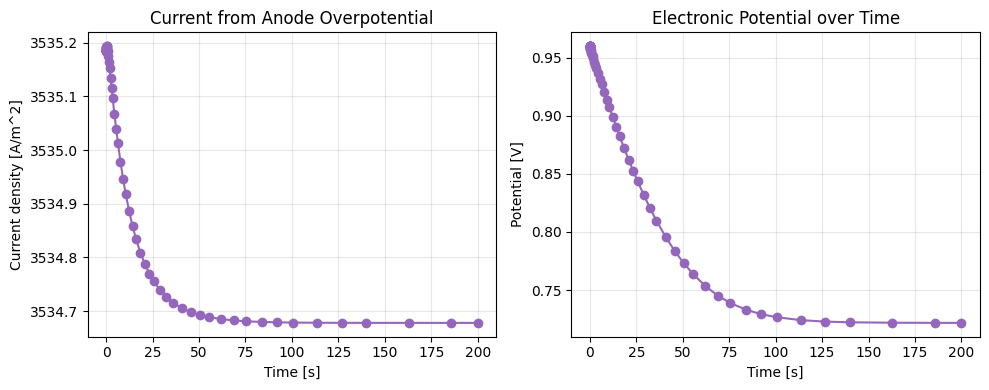

In [44]:
phi_el_all_time = y_plot[9, :]
eta_acl_alltime = y_plot[-5, :]
c_h2_alltime    = y_plot[-7, :]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

if cell.bc_mode == "potentiostatic":
    if cell.bc[Vars.phi_el]["cathode"]["left"].type == "dirichlet":
        phi_el_BC = cell.bc[Vars.phi_el]["cathode"]["left"].value
        j_t = -sigma_ca * (phi_el_all_time - phi_el_BC) / (dx_ca[0] / 2)
    elif cell.bc[Vars.phi_el]["cathode"]["left"].type == "neumann":
        j_t = -sigma_ca * cell.bc[Vars.phi_el]["cathode"]["left"].value
    ax1.plot(t_plot, j_t, "o-", color="tab:purple")
    ax1.set_title("Current from Electronic Potential BC")
elif cell.bc_mode == "galvanostatic":
    j_t = cell.BV_lumped(eta_acl_alltime, c_h2_alltime, "anode")
    ax1.plot(t_plot, j_t, "o-", color="tab:purple")
    ax1.set_title("Current from Anode Overpotential")
ax1.set_xlabel("Time [s]")
ax1.set_ylabel("Current density [A/m^2]")
ax1.grid(True, alpha=0.3)

ax2.plot(t_plot, phi_el_all_time, "o-", color="tab:purple")
ax2.set_title("Electronic Potential over Time")
ax2.set_xlabel("Time [s]")
ax2.set_ylabel("Potential [V]")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

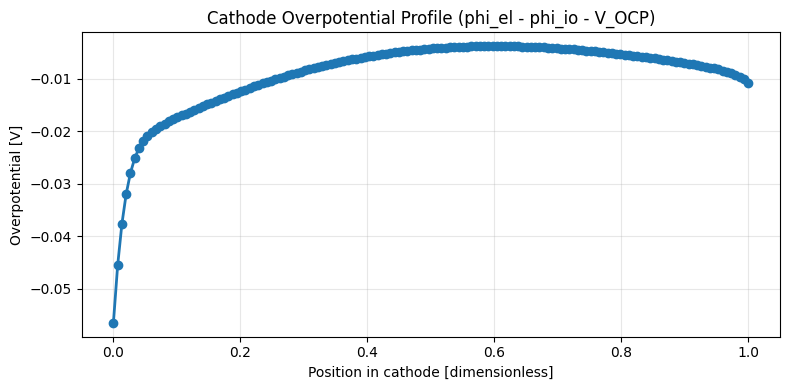

In [45]:
# Cathode overpotential profile: eta = phi_el_ca - phi_io_ca - V_OCP_ca
eta_ca = phi_el_ca - phi_io_ca - V_OCP_ca
plt.figure(figsize=(8, 4))
plt.plot(x_combined_ca, eta_ca, marker='o', lw=2)
plt.xlabel('Position in cathode [dimensionless]')
plt.ylabel('Overpotential [V]')
plt.title('Cathode Overpotential Profile (phi_el - phi_io - V_OCP)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
lambda_mem = y_mem_all[:, 0, :]

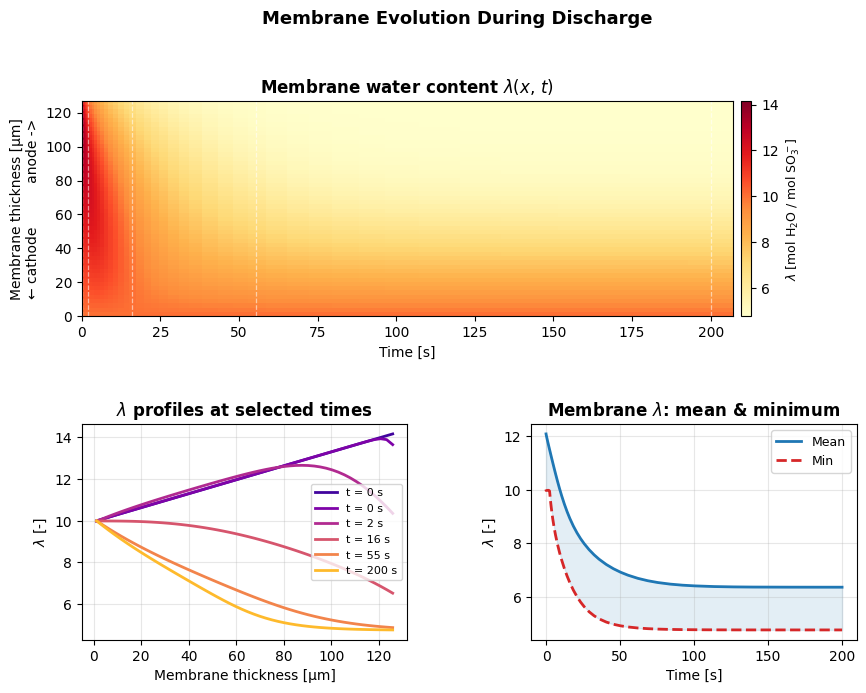

In [47]:
import matplotlib.gridspec as gridspec
# -- pick best available solution ---------------------------------------------
t_plot = tsol
y_plot = ysol
src_label = "continuation only"

Nm     = cell.mesh.membrane_mesh.n_x
n_mem  = cell.layout.n_vars_membrane
n_ca   = cell.layout.n_vars_cathode
Nc     = cell.mesh.cathode_mesh.n_x
n_tank = cell.layout.n_vars_tank
off_ca  = n_tank
off_mem = off_ca + Nc * n_ca
off_an  = off_mem + Nm * n_mem

# -- membrane fields: λ and Φ_io ----------------------------------------------
y_mem_all  = y_plot[off_mem:off_an, :].reshape(Nm, n_mem, -1)  # (Nm, 2, Nt)
lambda_mem = y_mem_all[:, 0, :]   # (Nm, Nt)
phi_io_mem = y_mem_all[:, 1, :]   # (Nm, Nt)

# physical x-coordinates for membrane nodes [µm]
dx_m   = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
edges  = np.concatenate([[0.0], np.cumsum(dx_m)])
x_mem  = 0.5 * (edges[:-1] + edges[1:]) * 1e6   # µm

# -- choose snapshot indices evenly spaced in time ----------------------------
n_snap = 6
t_idx  = np.round(np.linspace(0, len(t_plot) - 1, n_snap)).astype(int)
snap_colors = plt.cm.plasma(np.linspace(0.1, 0.85, n_snap))

# -- figure -------------------------------------------------------------------
fig = plt.figure(figsize=(10, 7))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.5, wspace=0.38)
ax_heat = fig.add_subplot(gs[0, :])   # full-width heatmap
ax_snap = fig.add_subplot(gs[1, 0])   # spatial snapshots
ax_mean = fig.add_subplot(gs[1, 1])   # mean & min over time

# -- 1. heatmap λ(x, t) -------------------------------------------------------
im = ax_heat.pcolormesh(t_plot, x_mem, lambda_mem, cmap="YlOrRd", shading="auto")
cb = fig.colorbar(im, ax=ax_heat, pad=0.01)
cb.set_label(r"$\lambda$ [mol H$_2$O / mol SO$_3^-$]", fontsize=9)
for idx in t_idx:
    ax_heat.axvline(t_plot[idx], color="white", lw=0.9, ls="--", alpha=0.55)
ax_heat.set_xlabel("Time [s]")
ax_heat.set_ylabel("Membrane thickness [µm]\n← cathode          anode ->")
ax_heat.set_title(r"Membrane water content $\lambda(x,\,t)$", fontweight="bold")

# -- 2. λ profiles at selected times ------------------------------------------
for k, idx in enumerate(t_idx):
    ax_snap.plot(x_mem, lambda_mem[:, idx], color=snap_colors[k], lw=2,
                 label=f"t = {t_plot[idx]:.0f} s")
ax_snap.set_xlabel("Membrane thickness [µm]")
ax_snap.set_ylabel(r"$\lambda$ [-]")
ax_snap.set_title(r"$\lambda$ profiles at selected times", fontweight="bold")
ax_snap.legend(fontsize=8, loc="best")
ax_snap.grid(True, alpha=0.3)

# -- 3. mean & minimum λ over time --------------------------------------------
lam_mean = np.mean(lambda_mem, axis=0)
lam_min  = np.min(lambda_mem,  axis=0)
ax_mean.plot(t_plot, lam_mean, lw=2, color="tab:blue",   label="Mean")
ax_mean.plot(t_plot, lam_min,  lw=2, color="tab:red", ls="--", label="Min")
ax_mean.fill_between(t_plot, lam_min, lam_mean, alpha=0.12, color="tab:blue")
ax_mean.set_xlabel("Time [s]")
ax_mean.set_ylabel(r"$\lambda$ [-]")
ax_mean.set_title(r"Membrane $\lambda$: mean & minimum", fontweight="bold")
ax_mean.legend(fontsize=9)
ax_mean.grid(True, alpha=0.3)

fig.suptitle("Membrane Evolution During Discharge", fontsize=13, fontweight="bold", y=1.01)
plt.show()